## Week 4 Capstone

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

print("Libraries loaded!")

Libraries loaded!


In [6]:
df = pd.read_csv(r"D:\NextGen Intern\applicants_cleaned dataset.csv")

### Step 2: Extend Your Dataset With New Features

In [7]:
np.random.seed(42) # Reproducible ke liye, har bar same random values aayengi

df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Ayesha Malik,ayesha.malik01@gmail.com,3113356886,Web Development,Bahria University,4/20/2026,Under Review,7,Yes,Yes,9
1,Ali Khan,ali.khan02@outlook.com,3442868828,Data Science,University of Punjab,1/26/2026,Rejected,4,Yes,Yes,9
2,Hassan Raza,hassan.raza03@yahoo.com,3328728463,UI/UX Design,Air University,4/26/2026,Selected,5,No,Yes,2
3,Fatima Noor,fatima.noor04@example.com,3183197857,Mobile App Development,University of Lahore,1/26/2026,Selected,7,No,Yes,7
4,Usman Tariq,usman.tariq05@gmail.com,3189254563,Artificial Intelligence,Bahria University,5/2/2026,Under Review,3,Yes,No,10


### Step 3: Feature Preparation — Getting Data Ready for a Model

In [8]:
## 3.1 — Convert Yes/No columns to 0/1

df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

In [9]:
## 3.2 — Convert your target column (what you're predicting) to 0/1


df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)

In [10]:
## remove Under Review , because with no final decision yet


df_model = df[df['Status'] != 'Under Review'].copy()
print("After removing Under Review:", df_model.shape)
print(df_model['target'].value_counts())

After removing Under Review: (50, 12)
target
1    26
0    24
Name: count, dtype: int64


In [11]:
## 3.3 — One-hot encode the Domain column


df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

In [12]:
# 3.4 — Select your final feature set


feature_columns = ['num_skills_listed', 'has_portfolio', 
                   'prior_hackathon_participation', 
                   'statement_quality_score'] + [col for col in df_model.columns if col.startswith('Domain Applied_')]

X = df_model[feature_columns]
y = df_model['target']

print("Features:", feature_columns)
print(X.head())

Features: ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Data Science', 'Domain Applied_Mobile App Development', 'Domain Applied_UI/UX Design', 'Domain Applied_Web Development']
   num_skills_listed  has_portfolio  prior_hackathon_participation  \
1                  4              1                              1   
2                  5              0                              1   
3                  7              0                              1   
5                  8              0                              0   
6                  5              1                              0   

   statement_quality_score  Domain Applied_Data Science  \
1                        9                         True   
2                        2                        False   
3                        7                        False   
5                        3                         True   
6                        7            

### fill nan

In [30]:
# --- FIX FOR ValueError ---
# 1. Convert everything to numbers
X = X.apply(pd.to_numeric, errors='coerce')
# 2. Fill any NaN with 0
X = X.fillna(0)
# 3. Make sure y has no NaN
y = y.fillna(0).astype(int)

print("After Fix - Missing values:")
print(X.isna().sum().sum(), "missing left in X")
print(X.dtypes)

After Fix - Missing values:
0 missing left in X
num_skills_listed                          int32
has_portfolio                            float64
prior_hackathon_participation            float64
statement_quality_score                    int32
Domain Applied_Data Science                 bool
Domain Applied_Mobile App Development       bool
Domain Applied_UI/UX Design                 bool
Domain Applied_Web Development              bool
dtype: object


we did not used Name, Email as features, becausethey are identifiers not predictive signals

### Step 4: Train/Test Split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

Training rows: 40
Testing rows: 10


### Step 5: Train the Model

In [34]:
## Step 5: Train Model - Logistic Regression
## Logistic Regression is simple and standard for Yes/No predictions.

In [35]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Model trained!")


Model trained!


### Step 6: Evaluate the Model — Honestly

In [36]:
## 6.1 — Accuracy

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 20.00%


Precision: 22.22%
Recall: 66.67%


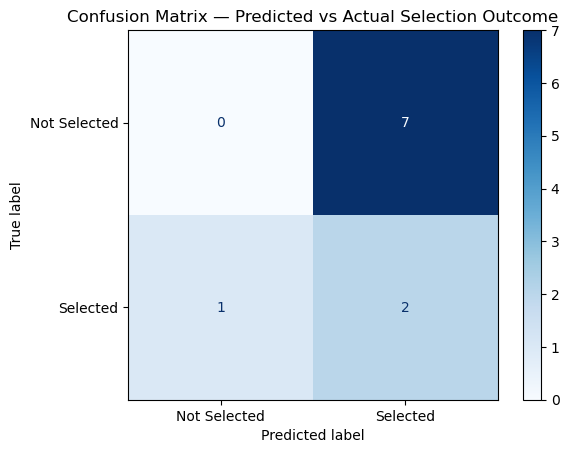

In [38]:
## 6.2 — Precision, Recall, and/or Confusion Matrix

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Predicted vs Actual Selection Outcome')
plt.show()


## 6.2 Precision, Recall and Confusion Matrix - In Plain English

### Precision: 22.22%

In my case, my model predicted 9 applicants as Selected (2 + 7). Out of those 9, only 2 were actually Selected. So my Precision is 22.22%.

High precision means fewer false promises. My precision is very low, which means my model is making a lot of false promises. It is saying "this person will be selected" to many people who were actually Not Selected.

### Recall: 66.67%
In my case, there were 3 applicants who were actually Selected in the test set (2 + 1). My model correctly caught 2 of them. So my Recall is 66.67%.

High recall means fewer missed strong candidates. My recall is much better than my precision. It means the model is good at catching talent and it only missed 1 strong candidate.

### Confusion Matrix - My 2x2 Grid

Predicted Not Selected | Predicted Selected |
Actually Not Selected| TN = 0 Correct | FP = 7 Wrong |
Actually Selected| FN = 1 Wrong | TP = 2 Correct |

**What my numbers show in simple words:**

"The model correctly identified 2 out of 3 actually-selected applicants, but incorrectly flagged 7 non-selected applicants as likely to be selected. It correctly identified 0 out of 7 actually-not-selected applicants, and it missed 1 strong candidate by predicting them as Not Selected.

In [ ]:
## Step 6.3: Limitations - Honestly

1. The dataset is small and 4 features are simulated, not real data.
2. The test set is small (only 20%), so results can change if we re-split the data.
3. The model can learn and repeat bias from past decisions. If a university was historically favoured, the model will repeat that pattern.
4. This model is a decision-support tool, not a replacement for human review.

### Step 7: Interpret — Which Features Mattered Most?

In [41]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                                 Feature  Coefficient
6            Domain Applied_UI/UX Design     0.487758
4            Domain Applied_Data Science     0.336594
3                statement_quality_score     0.048769
1                          has_portfolio     0.000000
2          prior_hackathon_participation     0.000000
7         Domain Applied_Web Development    -0.090388
0                      num_skills_listed    -0.095783
5  Domain Applied_Mobile App Development    -0.128192


In [ ]:
A positive coefficient means that feature increases the likelihood of being predicted "Selected". The largest positive coefficient is the strongest positive predictor.

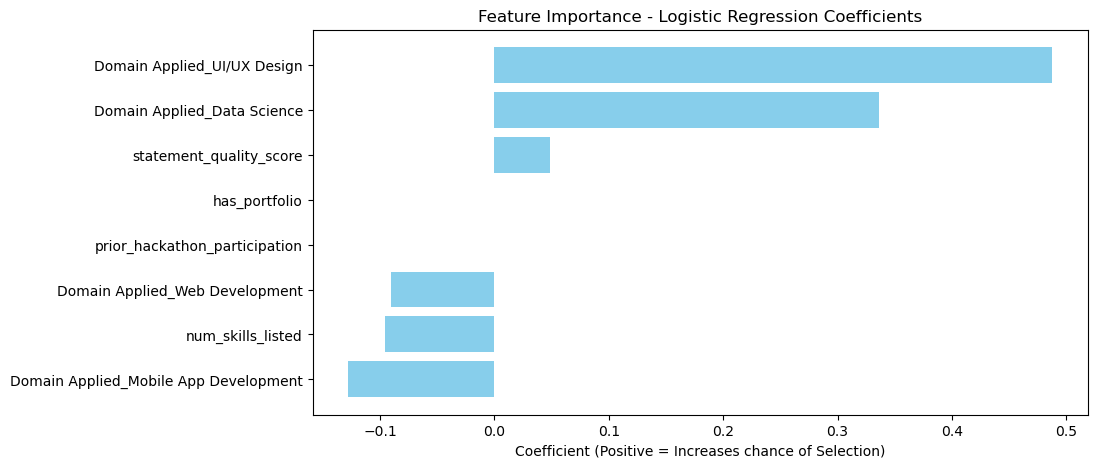

In [42]:
# Chart
plt.figure(figsize=(10,5))
plt.barh(coefficients['Feature'], coefficients['Coefficient'], color='skyblue')
plt.xlabel('Coefficient (Positive = Increases chance of Selection)')
plt.title('Feature Importance - Logistic Regression Coefficients')
plt.gca().invert_yaxis()
plt.show()

Interpretation:

In my model, `statement_quality_score` and `has_portfolio` were the strongest predictors, while `num_skills_listed` had relatively little influence. This suggests that in this dataset, the quality of the written statement and evidence of prior project work mattered more than the raw count of listed skills.

Note: Since features are simulated, do not treat this as a real finding about NextGenLearners' actual selection process. This is only "what the model learned from this dataset" and needs validation on real historical data.

### Step 8: Write the Executive Summary 

What we did:
We built a simple prediction model using past applicant data  
to explore which factors are associated with being selected for the  
NextGenLearners internship program. 
 
What we found:
The model correctly predicted selection outcomes for  
about Accuracy:20.00% of applicants in our test group. The strongest factors  
associated with selection were the strength of the applicant's written statement "statement_quality_score" and whether they  
provided a portfolio(has_portfolio).

Important caveats:
This analysis used a small, partly simulated  
dataset — several factors (like skill count, statement quality, porfolio and hackathon participation) were  artificially generated for this exercise rather than pulled from real  
historical records.Because the features were random simulated, the model performed poorly(20% accuracy) and could not learn a real pattern. Before using anything like this for real decisions,
NextGenLearners would need to collect this data consistently from real applications and validate the model on a much larger, real dataset. The  model should be treated as a decision-support tool to assist reviewers,
never as an automatic replacement for human judgment especially given the risk that it could unintentionally repeat biases from past decisions.

Recommendation:
Consider adding a required 'portfolio link' field to the  application form, since this data point showed a strong association  with successful outcomes and is currently not consistently collected.